In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

<Figure size 1500x800 with 0 Axes>

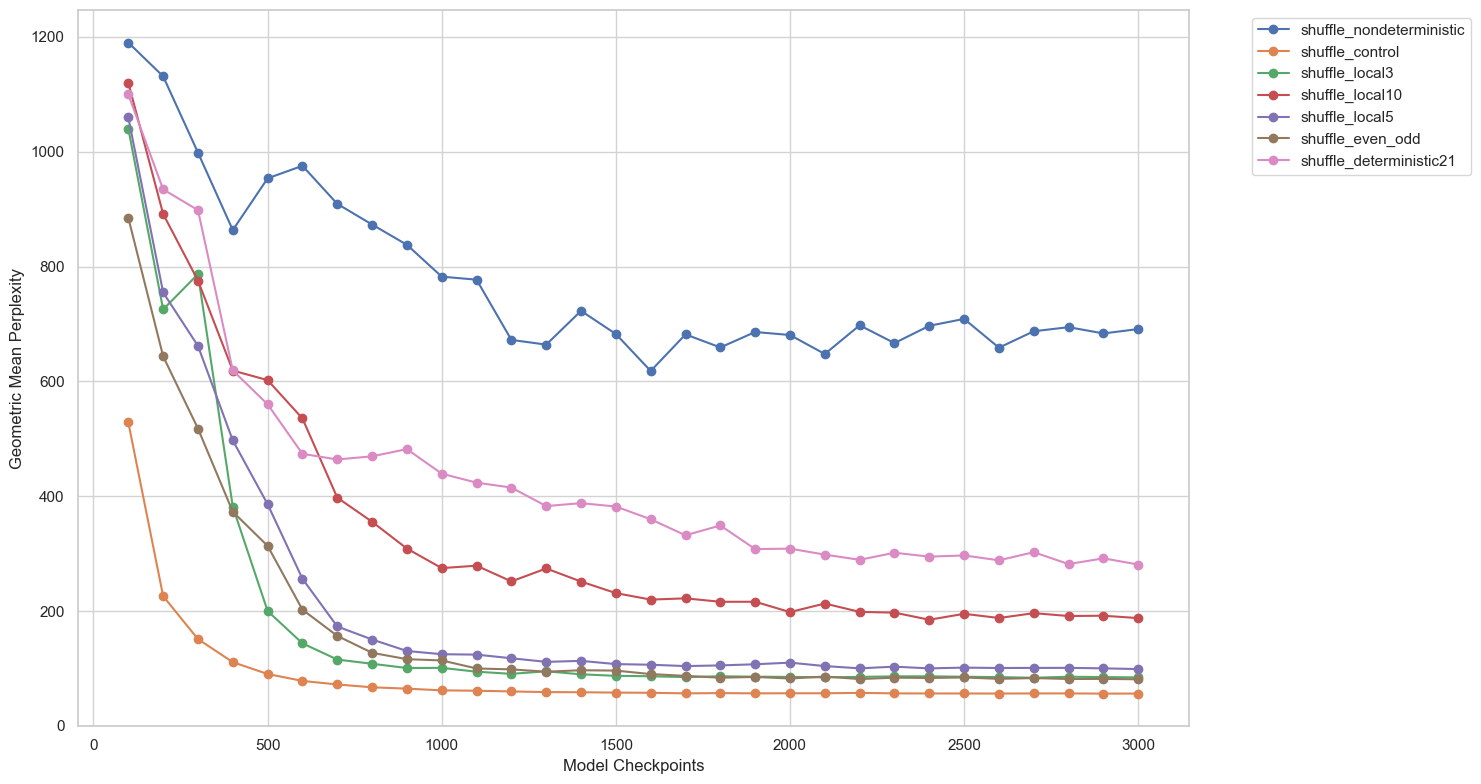


Perplexity Statistics by File

File: /home/s2587034/dissertation/code/perplexities/perplexity_results/shuffle_nondeterministic_100M/randinit_seed0_test_shuffle_nondeterministic.csv
  Error processing file: name 'mean_ppl' is not defined

File: /home/s2587034/dissertation/code/perplexities/perplexity_results/shuffle_control_100M/randinit_seed0_test_shuffle_control.csv
  Error processing file: name 'mean_ppl' is not defined

File: /home/s2587034/dissertation/code/perplexities/perplexity_results/reverse_full_100M/randinit_seed0_test_reverse_full.csv
  No 'Perplexities' columns found

File: /home/s2587034/dissertation/code/perplexities/perplexity_results/shuffle_local3_100M/randinit_seed0_test_shuffle_local3.csv
  Error processing file: name 'mean_ppl' is not defined

File: /home/s2587034/dissertation/code/perplexities/perplexity_results/shuffle_local10_100M/randinit_seed0_test_shuffle_local10.csv
  Error processing file: name 'mean_ppl' is not defined

File: /home/s2587034/dissertation/c

In [3]:
import os
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

# Set up the plotting style
sns.set(style="whitegrid")
plt.figure(figsize=(15, 8))

# Base directory containing all the experiment folders
base_dir = "/home/s2587034/dissertation/code/perplexities/perplexity_results"

# Find all matching files recursively
file_pattern = os.path.join(base_dir, "**", "randinit_seed0_test_*.csv")
files = glob.glob(file_pattern, recursive=True)

if not files:
    raise FileNotFoundError(f"No files found matching pattern: {file_pattern}")
files = [i for i in files if "reverse_control" not in i]

# Create a figure
plt.figure(figsize=(15, 8))
# labels = ["NonDeterministicShuffle", "ShuffleControl", "ShuffleLocal5", "DeterministicShuffle21"]
# Process each file
for it, file_path in enumerate(files):
    # Extract a label from the file path (using the parent directory name)
    parent_dir = os.path.basename(os.path.dirname(file_path))
    file_name = os.path.basename(file_path)
    label = f"{parent_dir}/{file_name.replace('randinit_seed0_test_', '').replace('.csv', '')}".split('/')[-1]
    
    try:
        # Load the CSV file
        df = pd.read_csv(file_path)
        
        # Extract checkpoint columns
        checkpoint_columns = [col for col in df.columns if 'Perplexities' in col]
        if not checkpoint_columns:
            print(f"Warning: No 'Perplexities' columns found in {file_path}")
            continue
            
        checkpoints = [int(col.split(' ')[-1].strip(')')) for col in checkpoint_columns]
        
        # Calculate statistics
        gmean_ppl = df[checkpoint_columns].apply(lambda x: stats.gmean(x))
        
        # Plot the mean perplexity for this file
        # plt.plot(checkpoints, gmean_ppl, marker='o', label=labels[it])
        plt.plot(checkpoints, gmean_ppl, marker='o', label=label)
        
    except Exception as e:
        print(f"Error processing {file_path}: {str(e)}")
        continue

# Add labels and title
plt.xlabel('Model Checkpoints', fontsize=12)
plt.ylabel('Geometric Mean Perplexity', fontsize=12)
# plt.title('', fontsize=14)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, color="lightgray")

# Adjust layout to make room for the legend
plt.tight_layout()

# Display the plot
plt.show()

# Print statistics for each file
print("\n" + "="*80)
print("Perplexity Statistics by File")
print("="*80)

for file_path in files:
    print(f"\nFile: {file_path}")
    try:
        df = pd.read_csv(file_path)
        checkpoint_columns = [col for col in df.columns if 'Perplexities' in col]
        if not checkpoint_columns:
            print("  No 'Perplexities' columns found")
            continue
            
        gmean_ppl = df[checkpoint_columns].apply(lambda x: stats.gmean(x))
        
        # Find the checkpoint with minimum perplexity
        min_mean_idx = mean_ppl.idxmin()
        min_mean_val = mean_ppl.min()
        min_mean_ckpt = int(min_mean_idx.split(' ')[-1].strip(')'))
        
        print(f"  Minimum mean perplexity: {min_mean_val:.2f} at checkpoint {min_mean_ckpt}")
        print(f"  Final mean perplexity: {mean_ppl.iloc[-1]:.2f}")
        
    except Exception as e:
        print(f"  Error processing file: {str(e)}")

<Figure size 1500x800 with 0 Axes>

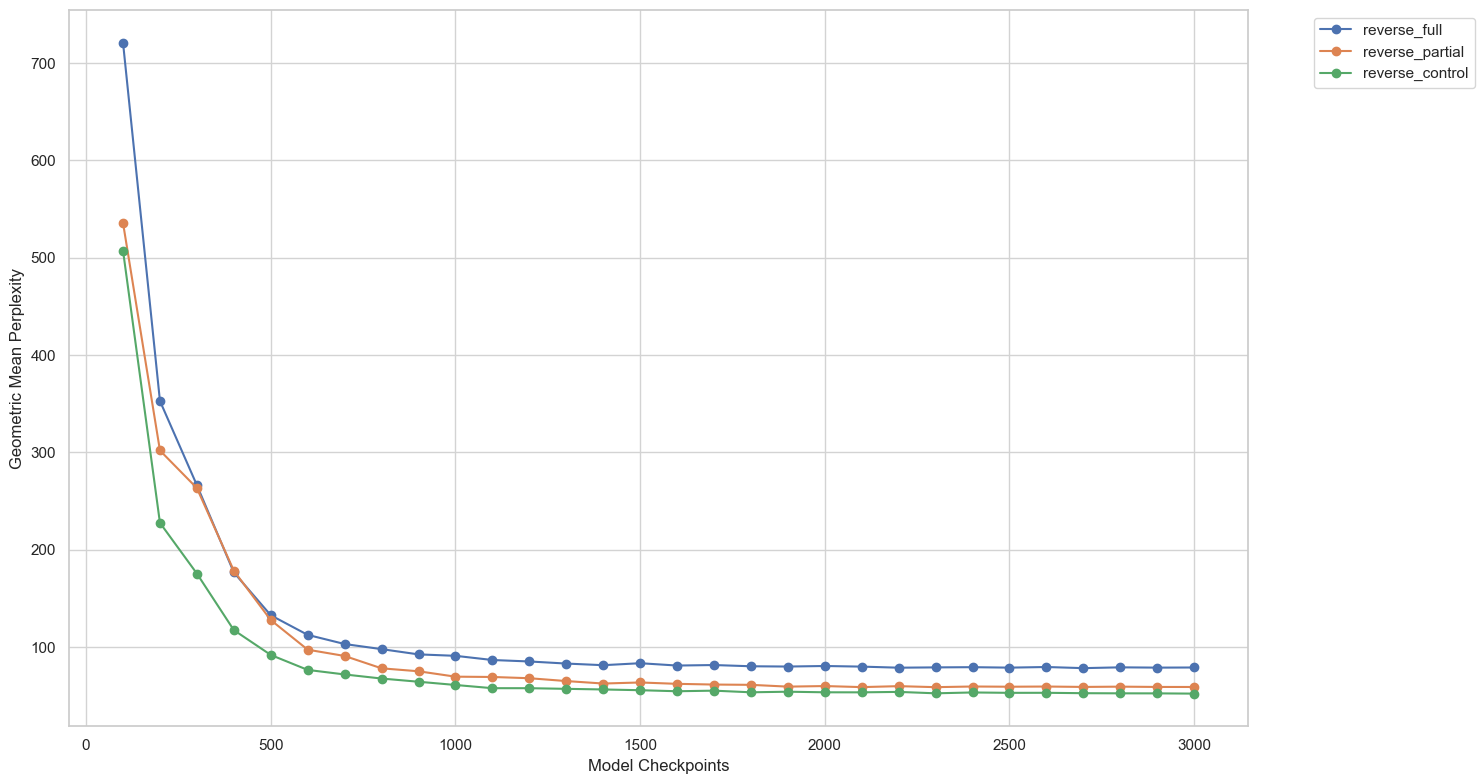


Perplexity Statistics by File

File: /home/s2587034/dissertation/code/perplexities/perplexity_results/reverse_full_100M/randinit_seed0_test_reverse_full.csv
  Error processing file: name 'mean_ppl' is not defined

File: /home/s2587034/dissertation/code/perplexities/perplexity_results/reverse_partial_100M/randinit_seed0_test_reverse_partial.csv
  Error processing file: name 'mean_ppl' is not defined

File: /home/s2587034/dissertation/code/perplexities/perplexity_results/reverse_control_100M/randinit_seed0_test_reverse_control.csv
  Error processing file: name 'mean_ppl' is not defined


In [1]:
import os
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

# Set up the plotting style
sns.set(style="whitegrid")
plt.figure(figsize=(15, 8))

# Base directory containing all the experiment folders
base_dir = "/home/s2587034/dissertation/code/perplexities/perplexity_results"

# Find all matching files recursively
file_pattern = os.path.join(base_dir, "**", "randinit_seed0_test_*.csv")
files = glob.glob(file_pattern, recursive=True)

if not files:
    raise FileNotFoundError(f"No files found matching pattern: {file_pattern}")
files = [i for i in files if "reverse" in i]

# Create a figure
plt.figure(figsize=(15, 8))
# labels = ["NonDeterministicShuffle", "ShuffleControl", "ShuffleLocal5", "DeterministicShuffle21"]
# Process each file
for it, file_path in enumerate(files):
    # Extract a label from the file path (using the parent directory name)
    parent_dir = os.path.basename(os.path.dirname(file_path))
    file_name = os.path.basename(file_path)
    label = f"{parent_dir}/{file_name.replace('randinit_seed0_test_', '').replace('.csv', '')}".split('/')[-1]
    
    try:
        # Load the CSV file
        df = pd.read_csv(file_path)
        
        # Extract checkpoint columns
        checkpoint_columns = [col for col in df.columns if 'Perplexities' in col]
        if not checkpoint_columns:
            print(f"Warning: No 'Perplexities' columns found in {file_path}")
            continue
            
        checkpoints = [int(col.split(' ')[-1].strip(')')) for col in checkpoint_columns]
        
        # Calculate statistics
        gmean_ppl = df[checkpoint_columns].apply(lambda x: stats.gmean(x))
        
        # Plot the mean perplexity for this file
        # plt.plot(checkpoints, gmean_ppl, marker='o', label=labels[it])
        plt.plot(checkpoints, gmean_ppl, marker='o', label=label)
        
    except Exception as e:
        print(f"Error processing {file_path}: {str(e)}")
        continue

# Add labels and title
plt.xlabel('Model Checkpoints', fontsize=12)
plt.ylabel('Geometric Mean Perplexity', fontsize=12)
# plt.title('', fontsize=14)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, color="lightgray")

# Adjust layout to make room for the legend
plt.tight_layout()

# Display the plot
plt.show()

# Print statistics for each file
print("\n" + "="*80)
print("Perplexity Statistics by File")
print("="*80)

for file_path in files:
    print(f"\nFile: {file_path}")
    try:
        df = pd.read_csv(file_path)
        checkpoint_columns = [col for col in df.columns if 'Perplexities' in col]
        if not checkpoint_columns:
            print("  No 'Perplexities' columns found")
            continue
            
        gmean_ppl = df[checkpoint_columns].apply(lambda x: stats.gmean(x))
        
        # Find the checkpoint with minimum perplexity
        min_mean_idx = mean_ppl.idxmin()
        min_mean_val = mean_ppl.min()
        min_mean_ckpt = int(min_mean_idx.split(' ')[-1].strip(')'))
        
        print(f"  Minimum mean perplexity: {min_mean_val:.2f} at checkpoint {min_mean_ckpt}")
        print(f"  Final mean perplexity: {mean_ppl.iloc[-1]:.2f}")
        
    except Exception as e:
        print(f"  Error processing file: {str(e)}")

In [19]:
from tokenizers import Tokenizer
import torch
tmp = df['Sentences'].tolist()
tmp = [x.split() for x in tmp]
# tmp = [int(i) for i in tmp]
# tmp[0]

In [20]:
tokenizer_path = "/home/s2587034/dissertation/models/custom_tokenizer/tokenizer.json"
tokenizer = Tokenizer.from_file(tokenizer_path)

for i, s in enumerate(tmp):
    test = [int(x) for x in s]
#     tmp = [int(x) for x in s.split()]
    token_ids = torch.tensor(test)
    print(f"line {i}: original dev sentence: {s}")
    print(f"line {i}: token_ids: {test}")
    decoded = tokenizer.decode(test)
    print(f"line {i}: {decoded}")


line 0: original dev sentence: ['0', '545', '959', '34', '1']
line 0: token_ids: [0, 545, 959, 34, 1]
line 0: eguduk?
line 1: original dev sentence: ['0', '721', '1683', '3033', '8655', '515', '2839', '3734', '1410', '637', '1683', '310', '312', '409', '1683', '721', '1683', '721', '17', '1']
line 1: token_ids: [0, 721, 1683, 3033, 8655, 515, 2839, 3734, 1410, 637, 1683, 310, 312, 409, 1683, 721, 1683, 721, 17, 1]
line 1: ulai membawayan keterl G Utikel terbaik sekarang membaw tidakor tahu membawulai membawulai.
line 2: original dev sentence: ['0', '2465', '720', '1683', '6834', '1683', '3610', '434', '341', '9110', '34', '1']
line 2: token_ids: [0, 2465, 720, 1683, 6834, 1683, 3610, 434, 341, 9110, 34, 1]
line 2: itan bi membaw menetapkan membaw He n itu mitra?
line 3: original dev sentence: ['0', '1390', '6016', '304', '640', '17', '1']
line 3: token_ids: [0, 1390, 6016, 304, 640, 17, 1]
line 3:  jelas membenc keaku.
line 4: original dev sentence: ['0', '310', '312', '409', '1683', '

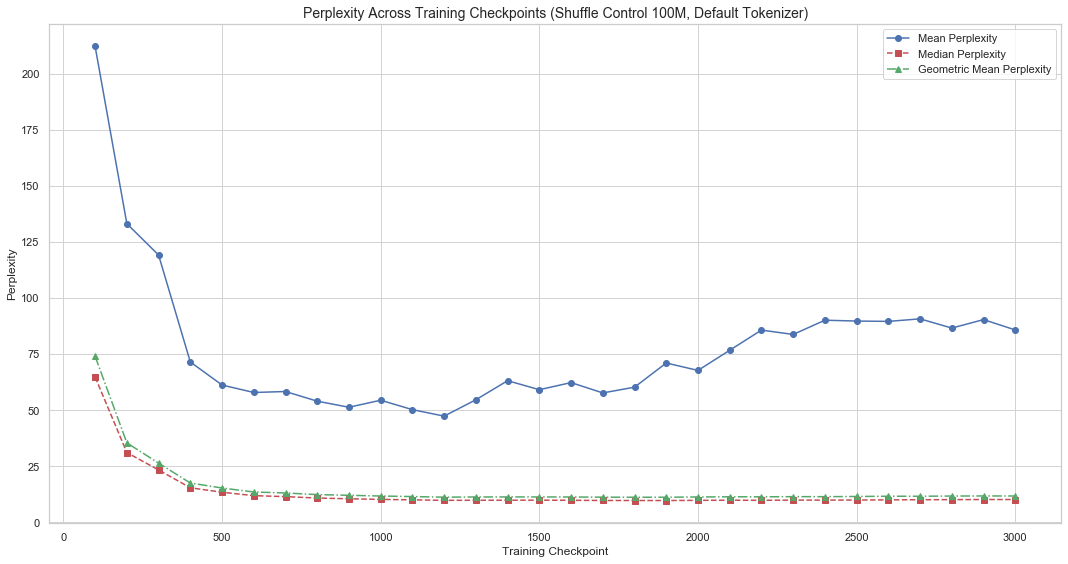


Perplexity Statistics by Checkpoint:
 Checkpoint        Mean     Median  Geometric Mean
        100  212.152250  64.707603       73.942425
        200  133.099962  31.033154       35.362160
        300  119.124924  23.285472       26.319235
        400   71.430271  15.330908       17.465987
        500   61.156040  13.347451       15.217215
        600   57.822745  11.822867       13.449666
        700   58.258653  11.382351       13.006437
        800   53.946357  10.756028       12.287403
        900   51.237150  10.420196       11.973944
       1000   54.375770  10.150963       11.655875
       1100   50.171909   9.939087       11.412629
       1200   47.276416   9.722732       11.142226
       1300   54.584557   9.759991       11.228661
       1400   63.087001   9.782751       11.243778
       1500   59.065713   9.806285       11.234239
       1600   62.239524   9.753874       11.221560
       1700   57.628260   9.661263       11.138420
       1800   60.190602   9.651149       11.

In [ ]:
# Set up the plotting style
sns.set(style="whitegrid")
plt.figure(figsize=(15, 8))

# Load the CSV file
file_path = "/home/s2587034/dissertation/code/perplexities/perplexity_results/shuffle_control_100M/def_tokenizer_randinit_seed0_test_shuffle_control.csv"
df = pd.read_csv(file_path)

# Extract checkpoint numbers from column names
checkpoint_columns = [col for col in df.columns if 'Perplexities' in col]
checkpoints = [int(col.split(' ')[-1].strip(')')) for col in checkpoint_columns]

# Calculate statistics
mean_ppl = df[checkpoint_columns].mean()
median_ppl = df[checkpoint_columns].median()
gmean_ppl = df[checkpoint_columns].apply(lambda x: stats.gmean(x))

# Create the plot
plt.plot(checkpoints, mean_ppl, 'b-', marker='o', label='Mean Perplexity')
plt.plot(checkpoints, median_ppl, 'r--', marker='s', label='Median Perplexity')
plt.plot(checkpoints, gmean_ppl, 'g-.', marker='^', label='Geometric Mean Perplexity')

# Add labels and title
plt.xlabel('Training Checkpoint', fontsize=12)
plt.ylabel('Perplexity', fontsize=12)
plt.title('Perplexity Across Training Checkpoints (Shuffle Control 100M, Default Tokenizer)', fontsize=14)
plt.legend()
plt.grid(True, color="lightgray")

# Display the plot
plt.tight_layout()
plt.show()

# Print a table of the results
results_df = pd.DataFrame({
    'Checkpoint': checkpoints,
    'Mean': mean_ppl.values,
    'Median': median_ppl.values,
    'Geometric Mean': gmean_ppl.values
})

print("\nPerplexity Statistics by Checkpoint:")
print(results_df.to_string(index=False))

# Find the checkpoint with minimum perplexity
min_mean_idx = mean_ppl.idxmin()
min_mean_val = mean_ppl.min()
min_mean_ckpt = int(min_mean_idx.split(' ')[-1].strip(')'))

print(f"\nMinimum mean perplexity: {min_mean_val:.2f} at checkpoint {min_mean_ckpt}")

In [8]:
df

,Unnamed: 0,Sentences,Perplexities (ckpt 100),Perplexities (ckpt 200),Perplexities (ckpt 300),Perplexities (ckpt 400),Perplexities (ckpt 500),Perplexities (ckpt 600),Perplexities (ckpt 700),Perplexities (ckpt 800),...,Perplexities (ckpt 2100),Perplexities (ckpt 2200),Perplexities (ckpt 2300),Perplexities (ckpt 2400),Perplexities (ckpt 2500),Perplexities (ckpt 2600),Perplexities (ckpt 2700),Perplexities (ckpt 2800),Perplexities (ckpt 2900),Perplexities (ckpt 3000)
0,0,Oh ya?,548.015442,179.677917,37.188099,25.888651,43.238583,25.715942,45.054283,26.936090,...,29.635170,25.318659,35.137569,32.534817,29.866547,33.698616,27.815968,34.332840,30.030508,30.823658
1,1,Baiklah . Um Lily memiliki studi cokelat nya s...,149.697327,57.548523,36.343491,29.922726,27.927231,25.946144,25.404140,24.926813,...,26.767271,27.315468,25.999138,26.022623,27.085159,26.080851,26.749172,26.895855,27.294182,26.765383
2,2,Yaah malam . Ohh . Film apa itu Roman?,593.422546,208.633469,193.508926,220.597733,202.673721,225.912415,236.305634,297.681000,...,198.994705,191.004318,187.214767,175.955948,181.596207,213.404770,203.583130,211.667114,199.049469,192.619171
3,3,maka pergilah ke sana.,122.909599,57.278427,19.051502,12.890162,9.589908,8.211497,6.591108,6.115968,...,11.528982,11.493156,11.039876,11.740515,12.892687,11.888333,12.176785,11.321005,11.245340,10.786774
4,4,Aku tidak tahu . lakukanlah ketiga-tiganya.,98.154488,47.398193,34.529034,36.550987,35.682018,32.746910,35.448380,34.203621,...,24.995169,24.771141,27.126642,24.457510,23.589796,24.524702,24.988125,25.021332,25.845278,26.069349
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,"Ia ia lahir pada tahun 1967, dan ia pertama ka...",95.377052,42.279346,29.143543,16.546518,11.803690,9.676790,9.738249,8.611401,...,6.862525,7.117108,6.810125,7.028696,7.228010,7.474634,7.608310,7.640187,7.436298,7.614545
9996,9996,"Saat jam berlalu, pelayan menjadi tidak sabar ...",60.082169,35.054100,28.190107,16.928633,13.204250,11.694455,10.875103,9.968542,...,6.846948,6.948390,7.027772,6.478908,6.736933,6.773896,6.833416,6.890708,6.841127,6.725907
9997,9997,"Beberapa tahun kemudian, Nettles pergi ke seko...",78.866707,33.362301,27.585382,13.589246,10.894517,8.640583,7.460124,6.425446,...,5.446745,5.861300,5.644261,6.042134,5.728663,5.877405,6.064829,5.981345,6.095683,6.089166
9998,9998,"Rumah ini terletak di Lummus Park, di sebelah ...",400.193451,281.352386,174.597397,78.255127,65.327545,37.661274,36.303200,30.890091,...,24.154741,25.132477,24.393593,23.961887,22.370321,27.232359,25.471296,26.235813,25.505211,25.317282


In [9]:
df = pd.read_csv("/home/s2587034/dissertation/code/perplexities/perplexity_results/shuffle_nondeterministic_100M/randinit_seed0_test_shuffle_nondeterministic.csv")
df

,Unnamed: 0,Sentences,Perplexities (ckpt 100),Perplexities (ckpt 200),Perplexities (ckpt 300),Perplexities (ckpt 400),Perplexities (ckpt 500),Perplexities (ckpt 600),Perplexities (ckpt 700),Perplexities (ckpt 800),...,Perplexities (ckpt 2100),Perplexities (ckpt 2200),Perplexities (ckpt 2300),Perplexities (ckpt 2400),Perplexities (ckpt 2500),Perplexities (ckpt 2600),Perplexities (ckpt 2700),Perplexities (ckpt 2800),Perplexities (ckpt 2900),Perplexities (ckpt 3000)
0,0,? ya Oh,2.745541e+05,1.226710e+06,1.193563e+06,4.070283e+06,2.998806e+06,2.301351e+06,3.237709e+06,2.266050e+06,...,3.762114e+06,3.577353e+06,4.181731e+06,4.892516e+06,7.215970e+06,5.439114e+06,8.351352e+06,7.764246e+06,7.337340e+06,7.065342e+06
1,1,. tidak Aku . nya memiliki . tahu Um Baiklah ....,3.362077e+06,1.722981e+07,1.873202e+07,4.349920e+07,6.292984e+07,8.984468e+07,4.031860e+07,2.451499e+07,...,5.028700e+07,4.062568e+07,5.196381e+07,4.137467e+07,2.745800e+07,3.995961e+07,4.406563e+07,3.429969e+07,3.046143e+07,3.076300e+07
2,2,apa itu Roman Yaah Ohh malam . . ? Film,1.940863e+06,1.192718e+07,1.767032e+07,3.343951e+07,3.648232e+07,2.785563e+07,3.548000e+07,3.678746e+07,...,9.995102e+07,1.104449e+08,8.420268e+07,1.290569e+08,1.234993e+08,1.200749e+08,1.572402e+08,1.305819e+08,1.322304e+08,1.345740e+08
3,3,sana maka . pergilah ke,1.357555e+05,4.278031e+05,5.708871e+05,8.707861e+05,1.196132e+06,1.467811e+06,1.597196e+06,1.078937e+06,...,1.996582e+06,2.124070e+06,1.820223e+06,2.500543e+06,2.014006e+06,2.125819e+06,2.254086e+06,2.381422e+06,2.118358e+06,2.040004e+06
4,4,ganya . lakukanlah Aku ketiga ti tahu tidak - .,1.558154e+06,8.040850e+06,1.094521e+07,2.254282e+07,2.761046e+07,3.120153e+07,2.853095e+07,1.989355e+07,...,6.013071e+07,6.319651e+07,5.993136e+07,5.702113e+07,5.093628e+07,6.135985e+07,5.669924e+07,5.149790e+07,4.655643e+07,4.657952e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,NaN,6.895163e+03,2.834879e+00,2.886710e+01,2.035184e+00,1.810466e+00,1.383467e+00,1.418053e+00,1.495801e+00,...,1.090349e+00,1.079463e+00,1.052385e+00,1.055533e+00,1.048201e+00,1.041796e+00,1.043134e+00,1.041087e+00,1.038421e+00,1.040260e+00
9996,9996,"dan Band Pride ette , dengan di wha bersaing C...",4.274526e+06,2.194774e+07,1.465329e+07,4.561651e+07,2.945162e+07,1.022552e+08,1.229592e+07,1.352845e+07,...,6.380962e+07,2.942293e+07,3.866184e+07,5.971274e+07,3.087386e+07,4.475000e+07,5.553433e+07,5.273955e+07,4.689509e+07,4.275869e+07
9997,9997,"nanti suatu di New tles mengundang , kayu Bria...",2.906088e+06,1.524463e+07,1.354381e+07,2.703019e+07,2.683565e+07,5.044888e+07,1.903096e+07,1.977130e+07,...,4.526506e+07,3.614556e+07,3.851743e+07,5.263845e+07,2.947820e+07,4.431503e+07,5.009382e+07,4.704883e+07,4.356704e+07,3.938484e+07
9998,9998,"Brown , Township South County . Edwards , Kansas",1.549584e+06,7.158518e+06,1.051920e+07,2.237367e+07,3.390533e+07,3.831775e+07,3.225577e+07,2.027134e+07,...,2.545065e+07,3.064710e+07,3.622562e+07,3.167572e+07,2.589620e+07,3.301150e+07,3.687971e+07,2.613328e+07,2.745187e+07,2.701875e+07


In [10]:
df = pd.read_csv("/home/s2587034/dissertation/code/perplexities/perplexity_results/shuffle_even_odd_10M/randinit_seed0_test_shuffle_even_odd.csv")
df

,Unnamed: 0,Sentences,Perplexities (ckpt 100),Perplexities (ckpt 200),Perplexities (ckpt 300),Perplexities (ckpt 400),Perplexities (ckpt 500),Perplexities (ckpt 600),Perplexities (ckpt 700),Perplexities (ckpt 800),...,Perplexities (ckpt 2100),Perplexities (ckpt 2200),Perplexities (ckpt 2300),Perplexities (ckpt 2400),Perplexities (ckpt 2500),Perplexities (ckpt 2600),Perplexities (ckpt 2700),Perplexities (ckpt 2800),Perplexities (ckpt 2900),Perplexities (ckpt 3000)
0,0,ya Oh ?,1.803525e+05,2.530901e+05,3.692824e+05,2.180683e+05,2.387138e+05,2.200947e+05,2.633887e+05,4.269631e+05,...,1.218857e+06,2.025552e+06,3.556040e+06,2.020141e+06,2.175431e+06,2.309440e+06,3.570710e+06,2.854830e+06,2.505819e+06,2.542340e+06
1,1,. Lily studi nya . tidak . . . Baiklah Um memi...,1.685010e+06,3.233642e+06,3.260418e+06,2.366970e+06,3.367481e+06,5.614366e+06,3.363023e+06,2.541310e+07,...,1.035424e+08,1.711057e+08,2.100362e+08,1.815809e+08,1.775296e+08,1.583931e+08,2.521617e+08,2.134830e+08,1.978183e+08,1.933026e+08
2,2,malam Ohh Film itu ? Yaah . . apa Roman,9.229053e+05,1.504413e+06,2.526265e+06,2.115416e+06,2.386044e+06,4.272952e+06,3.191248e+06,1.598404e+07,...,3.190741e+07,4.633045e+07,9.888855e+07,6.236906e+07,5.422884e+07,4.562112e+07,8.678431e+07,6.139813e+07,6.165443e+07,5.669828e+07
3,3,pergilah sana maka ke .,5.521741e+05,1.181669e+06,9.585629e+05,6.952179e+05,8.795086e+05,9.550499e+05,1.086459e+06,2.711494e+06,...,5.938634e+06,9.724327e+06,2.402226e+07,9.829932e+06,1.373921e+07,1.162503e+07,2.280320e+07,1.248724e+07,1.254541e+07,1.269254e+07
4,4,tidak . ketiga ti . Aku tahu lakukanlah - ganya,1.292018e+06,3.041958e+06,3.202495e+06,1.965265e+06,2.172452e+06,3.700451e+06,3.069625e+06,1.445357e+07,...,4.212429e+07,1.051820e+08,2.068864e+08,1.199284e+08,1.015037e+08,8.429267e+07,2.061954e+08,1.355258e+08,1.297401e+08,1.315353e+08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,NaN,1.518878e+03,1.059789e+03,1.914403e+03,6.800396e+02,4.442010e+02,9.011819e+02,7.482908e+02,6.171039e+02,...,9.967709e+02,9.263151e+02,1.133810e+03,1.353388e+03,1.078349e+03,9.342491e+02,1.169719e+03,1.233243e+03,1.180913e+03,1.078366e+03
9996,9996,of High bersama tujuh menengah lainnya Kana Co...,2.520285e+06,3.740841e+06,3.465683e+06,3.276492e+06,2.692284e+06,4.853267e+06,2.800777e+06,1.851537e+07,...,9.626378e+07,8.493240e+07,1.323780e+08,1.337464e+08,1.289398e+08,9.633431e+07,1.792684e+08,1.426055e+08,1.294400e+08,1.345037e+08
9997,9997,kayu Net membantunya dan mengundang Rose mengu...,1.747964e+06,3.426394e+06,3.643838e+06,2.838644e+06,2.310261e+06,4.127576e+06,2.651498e+06,1.464941e+07,...,4.721262e+07,6.301175e+07,1.018008e+08,9.852838e+07,9.905410e+07,7.735558e+07,1.429931e+08,1.268275e+08,1.108803e+08,1.229179e+08
9998,9998,"Brown , County Kansas South Township Edwards , .",1.121900e+06,2.364558e+06,3.364082e+06,1.607673e+06,1.693255e+06,2.914670e+06,2.513164e+06,9.837923e+06,...,2.629197e+07,3.614226e+07,6.904600e+07,4.955518e+07,4.350268e+07,4.332275e+07,8.151061e+07,4.991994e+07,4.944963e+07,4.857946e+07


In [11]:
df = pd.read_csv("/home/s2587034/dissertation/code/perplexities/perplexity_results/shuffle_nondeterministic_10M/randinit_seed0_test_shuffle_nondeterministic.csv")
df

,Unnamed: 0,Sentences,Perplexities (ckpt 100),Perplexities (ckpt 200),Perplexities (ckpt 300),Perplexities (ckpt 400),Perplexities (ckpt 500),Perplexities (ckpt 600),Perplexities (ckpt 700),Perplexities (ckpt 800),...,Perplexities (ckpt 2100),Perplexities (ckpt 2200),Perplexities (ckpt 2300),Perplexities (ckpt 2400),Perplexities (ckpt 2500),Perplexities (ckpt 2600),Perplexities (ckpt 2700),Perplexities (ckpt 2800),Perplexities (ckpt 2900),Perplexities (ckpt 3000)
0,0,? ya Oh,3.004183e+05,4.592201e+05,1.201011e+06,8.488032e+05,6.104542e+05,1.000418e+06,9.520889e+05,5.899579e+05,...,4.353320e+06,5.547972e+06,7.154327e+06,7.228809e+06,5.932832e+06,7.224728e+06,7.771002e+06,7.631366e+06,7.305759e+06,7.709564e+06
1,1,. tidak Aku . nya memiliki . tahu Um Baiklah ....,3.492371e+06,5.829171e+06,6.396416e+06,5.452388e+06,1.202057e+07,2.078747e+07,1.035068e+07,1.381760e+07,...,5.015929e+06,5.560484e+06,7.044686e+06,8.421701e+06,1.211713e+07,8.806177e+06,9.998872e+06,8.878834e+06,1.082186e+07,9.054549e+06
2,2,apa itu Roman Yaah Ohh malam . . ? Film,1.484334e+06,4.274286e+06,1.025195e+07,9.361645e+06,6.043901e+06,7.408886e+06,9.132216e+06,5.026454e+06,...,3.562905e+07,5.960817e+07,6.176600e+07,6.142648e+07,5.589020e+07,5.742475e+07,5.881188e+07,5.710396e+07,5.934860e+07,5.742935e+07
3,3,sana maka . pergilah ke,8.529160e+04,2.380697e+05,3.175820e+05,2.887726e+05,3.465106e+05,4.337227e+05,4.703698e+05,4.400482e+05,...,3.796738e+05,8.459159e+05,9.412696e+05,9.190039e+05,7.727447e+05,8.543590e+05,7.586198e+05,7.240624e+05,8.064508e+05,7.668540e+05
4,4,ganya . lakukanlah Aku ketiga ti tahu tidak - .,1.482496e+06,4.044073e+06,3.767542e+06,4.815765e+06,9.919812e+06,1.358106e+07,7.897390e+06,1.139566e+07,...,3.508740e+06,4.099668e+06,6.212024e+06,7.047367e+06,8.814537e+06,8.534718e+06,7.233843e+06,6.585302e+06,9.446018e+06,7.841748e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,NaN,2.642940e+03,1.043104e+01,8.500355e+00,2.947652e+00,2.749992e+00,2.428356e+00,1.736569e+00,1.520362e+00,...,1.115725e+00,1.087836e+00,1.082222e+00,1.090563e+00,1.098462e+00,1.075738e+00,1.082303e+00,1.072260e+00,1.081623e+00,1.077671e+00
9996,9996,"dan Band Pride ette , dengan di wha bersaing C...",3.600909e+06,6.301725e+06,6.690518e+06,4.246065e+06,6.391812e+06,7.480023e+06,3.017557e+06,8.072121e+06,...,1.398421e+07,2.490822e+07,3.540962e+07,3.595551e+07,5.688936e+07,3.778086e+07,2.586411e+07,3.206280e+07,3.881538e+07,3.661540e+07
9997,9997,"nanti suatu di New tles mengundang , kayu Bria...",3.015791e+06,4.455380e+06,3.802719e+06,5.651686e+06,1.375240e+07,1.118529e+07,6.049880e+06,2.056901e+07,...,6.410340e+06,1.103124e+07,1.198440e+07,1.715576e+07,1.116100e+07,1.464823e+07,1.711106e+07,1.664408e+07,1.574346e+07,1.604782e+07
9998,9998,"Brown , Township South County . Edwards , Kansas",1.313667e+06,3.563450e+06,3.695644e+06,4.901614e+06,8.677416e+06,1.688792e+07,1.041121e+07,1.948252e+07,...,7.343906e+06,7.839094e+06,1.327169e+07,1.552862e+07,1.585054e+07,1.517098e+07,1.340897e+07,1.190725e+07,1.371844e+07,1.233514e+07


## Debug

In [26]:
from datasets import Dataset
from tokenizers import Tokenizer
from transformers import AutoTokenizer
import torch

# shuffle_control validation
dataset_path = "/home/s2587034/pretrained_checkpoints/babylm_models/babylm_shuffle_control_10M_randinit/babylm_shuffle_control_10M_randinit_seed0/artifacts/datasets/baby_lm_corpus/babylm_shuffle_control_10M_seed0/0.0.0/7761ef8f3855a20ed4a8fb5d8a4b5ecb1aab61932eaef34060429d23583d311a/baby_lm_corpus-validation.arrow"
print(f"Loading validation data from {dataset_path}...")
dataset = Dataset.from_file(dataset_path)

tokenizer_path = "/home/s2587034/dissertation/models/custom_tokenizer/tokenizer.json"
tokenizer = Tokenizer.from_file(tokenizer_path)

for i, s in enumerate(dataset['text'][:1]):
    tmp = [int(x) for x in s.split()]
    # token_ids = torch.tensor(tmp)
    print(f"line {i}: original dev sentence: {s}")
    print(f"line {i}: token_ids: {tmp}")
    decoded = tokenizer.decode(tmp)
    print(f"line {i}: {decoded}")


Loading validation data from /home/s2587034/pretrained_checkpoints/babylm_models/babylm_shuffle_control_10M_randinit/babylm_shuffle_control_10M_randinit_seed0/artifacts/datasets/baby_lm_corpus/babylm_shuffle_control_10M_seed0/0.0.0/7761ef8f3855a20ed4a8fb5d8a4b5ecb1aab61932eaef34060429d23583d311a/baby_lm_corpus-validation.arrow...


line 0: original dev sentence: 0 310 320 2175 17 1 1 0 8469 536 351 521 320 653 341 17 1 1 0 442 707 1464 4410 947 15 297 602 3993 279 640 15 602 11237 15 297 602 312 408 677 15 297 602 998 279 640 908 1828 1043 797 385 1651 4656 602 17 1 1 0 12370 773 10728 15 12969 16 24808 12370 773 10728 373 563 3505 753 291 2037 279 2784 12969 16 24808 279 1905 2751 17 1 1 0 545 7371 442 602 897 2409 2987 602 769 17 1 1 0 6935 3514 2340 7989 493 3912 6475 3380 12 43678 5780 279 1168 1024 419 475 5125 17 1 1 0 474 15 336 465 441 17 1 1 0 2490 4 327 474 17 1 1 0 591 620 291 1046 2177 360 522 4386 333 1127 373 333 1856 3417 2681 429 6458 17 1 1 0 915 1091 17 1 1 0 6402 15 351 2393 342 602 17 1 1 0 4154 15 680 15 506 15 1988 4 4154 15 680 15 506 17 1 1 0 380 291 351 630 34 1 1 0 327 474 17 1 1 0 915 630 434 291 472 351 630 17 1 1 0 16696 15 857 34 1 1 0 490 41554 949 2061 17 1 1 0 310 21100 937 26577 16 295 15 297 1011 1624 8436 341 333 574 1787 26577 16 295 769 17 1 1 0 380 291 385 1833 34 1 1 0 453 

In [27]:
from datasets import Dataset
from tokenizers import Tokenizer
from transformers import AutoTokenizer
import torch

# shuffle_control train
dataset_path = "/home/s2587034/pretrained_checkpoints/babylm_models/babylm_shuffle_control_10M_randinit/babylm_shuffle_control_10M_randinit_seed0/artifacts/datasets/baby_lm_corpus/babylm_shuffle_control_10M_seed0/0.0.0/7761ef8f3855a20ed4a8fb5d8a4b5ecb1aab61932eaef34060429d23583d311a/baby_lm_corpus-train.arrow"
print(f"Loading training data from {dataset_path}...")
dataset = Dataset.from_file(dataset_path)

tokenizer_path = "/home/s2587034/dissertation/models/custom_tokenizer/tokenizer.json"
tokenizer = Tokenizer.from_file(tokenizer_path)

for i, s in enumerate(dataset['text'][:1]):
    tmp = [int(x) for x in s.split()]
    # token_ids = torch.tensor(tmp)
    print(f"line {i}: original dev sentence: {s}")
    print(f"line {i}: token_ids: {tmp}")
    decoded = tokenizer.decode(tmp)
    print(f"line {i}: {decoded}")


Loading training data from /home/s2587034/pretrained_checkpoints/babylm_models/babylm_shuffle_control_10M_randinit/babylm_shuffle_control_10M_randinit_seed0/artifacts/datasets/baby_lm_corpus/babylm_shuffle_control_10M_seed0/0.0.0/7761ef8f3855a20ed4a8fb5d8a4b5ecb1aab61932eaef34060429d23583d311a/baby_lm_corpus-train.arrow...
line 0: original dev sentence: 0 1631 506 3562 7371 1 1 0 612 9592 1672 297 341 373 1121 360 4229 626 1232 360 568 522 3059 2103 15 531 342 743 3059 10591 360 9592 297 707 7038 2401 297 33202 10591 360 9592 15 297 6854 976 4627 9592 669 279 1467 23920 291 1358 387 409 522 11842 360 1448 531 387 582 16 668 2089 333 782 333 948 387 769 17 1 1 0 429 1758 16 21775 832 5656 1718 2870 17 1 1 0 380 34 1 1 0 310 1302 224 34 1 1 0 2287 5747 548 19919 645 308 493 39691 291 992 637 8628 455 16 8941 1660 12 312 409 2800 456 992 279 3574 788 566 454 291 753 567 1941 2527 17 1 1 0 663 2925 367 312 408 508 1085 1197 8407 291 3373 17 1 1 0 1210 536 9953 34 1 1 0 1117 16 1022 556 429

In [22]:
# testing babylm_data_perturbed/babylm_shuffle_control/babylm_dev/aochildes.dev
with open("/home/s2587034/dissertation/dataset/clean_data/nllb/babylm_data_ind/babylm_data_perturbed/babylm_shuffle_control/babylm_dev/aochildes.dev", "r") as f:
    lines = f.readlines()
print(lines[0], type(lines[0]))

tokenizer_path = "/home/s2587034/dissertation/models/custom_tokenizer/tokenizer.json"
tokenizer = Tokenizer.from_file(tokenizer_path)

for i, s in enumerate(lines[:1]):
    tmp = [int(x) for x in s.split()]
    # token_ids = torch.tensor(tmp)
    print(f"line {i}: original dev sentence: {s}")
    print(f"line {i}: token_ids: {tmp}")
    decoded = tokenizer.decode(tmp)
    print(f"line {i}: {decoded}")

0 310 486 1002 357 1568 5256 536 43134 17 1
 <class 'str'>
line 0: original dev sentence: 0 310 486 1002 357 1568 5256 536 43134 17 1

line 0: token_ids: [0, 310, 486, 1002, 357, 1568, 5256, 536, 43134, 17, 1]
line 0:  Aku lebih suka ini daripada sepeda atau buldoser.


In [23]:
# testing babylm_data_perturbed/babylm_shuffle_deterministic21/babylm_dev/aochildes.dev
with open("/home/s2587034/dissertation/dataset/clean_data/nllb/babylm_data_ind/babylm_data_perturbed/babylm_shuffle_deterministic21/babylm_dev/aochildes.dev", "r") as f:
    lines = f.readlines()
print(lines[0], type(lines[0]))

tokenizer_path = "/home/s2587034/dissertation/models/custom_tokenizer/tokenizer.json"
tokenizer = Tokenizer.from_file(tokenizer_path)

for i, s in enumerate(lines[:1]):
    tmp = [int(x) for x in s.split()]
    # token_ids = torch.tensor(tmp)
    print(f"line {i}: original dev sentence: {s}")
    print(f"line {i}: token_ids: {tmp}")
    decoded = tokenizer.decode(tmp)
    print(f"line {i}: {decoded}")

536 0 1 1568 43134 310 1002 357 17 5256 486
 <class 'str'>
line 0: original dev sentence: 536 0 1 1568 43134 310 1002 357 17 5256 486

line 0: token_ids: [536, 0, 1, 1568, 43134, 310, 1002, 357, 17, 5256, 486]
line 0:  atau daripada buldoser Aku suka ini. sepeda lebih


In [4]:
from datasets import Dataset
from tokenizers import Tokenizer
from transformers import AutoTokenizer
import torch

with open("/home/s2587034/dissertation/dataset/clean_data/nllb/babylm_data_ind/babylm_data_perturbed/babylm_shuffle_control/babylm_test_affected/aochildes_affected.test") as f:
    lines = f.readlines()
print(lines[0], type(lines[0]))

tokenizer_path = "/home/s2587034/dissertation/models/custom_tokenizer/tokenizer.json"
tokenizer = Tokenizer.from_file(tokenizer_path)

for i, s in enumerate(lines[:1]):
    tmp = [int(x) for x in s.split()]
    # token_ids = torch.tensor(tmp)
    print(f"line {i}: original dev sentence: {s}")
    print(f"line {i}: token_ids: {tmp}")
    decoded = tokenizer.decode(tmp)
    print(f"line {i}: {decoded}")

/home/s2587034/.conda/envs/dissertation/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


0 1437 346 1178 618 500 19449 1322 17 1
 <class 'str'>
line 0: original dev sentence: 0 1437 346 1178 618 500 19449 1322 17 1

line 0: token_ids: [0, 1437, 346, 1178, 618, 500, 19449, 1322, 17, 1]
line 0:  Kurasa kau belum pernah melihat kanguru sebelumnya.


In [5]:
file_token_sequences = [[int(s) for s in l.split()] for l in lines]
file_token_sequences

[[0, 1437, 346, 1178, 618, 500, 19449, 1322, 17, 1],
 [0,
  38099,
  1600,
  393,
  409,
  428,
  356,
  34,
  323,
  373,
  224,
  34,
  535,
  20944,
  428,
  4578,
  6682,
  500,
  5886,
  616,
  356,
  224,
  34,
  535,
  34,
  1],
 [0, 535, 298, 4810, 5886, 34, 1],
 [0, 373, 224, 34, 38099, 224, 34, 417, 15, 341, 581, 17, 1],
 [0, 393, 409, 428, 291, 1293, 19449, 17, 1],
 [0, 659, 2198, 17, 1],
 [0, 393, 407, 2198, 224, 34, 417, 15, 341, 581, 17, 1],
 [0, 475, 291, 1293, 19449, 17, 1],
 [0, 1006, 385, 823, 428, 643, 291, 429, 34, 1],
 [0, 393, 409, 428, 356, 34, 1],
 [0, 373, 341, 4801, 224, 34, 1],
 [0, 393, 581, 341, 1013, 464, 4801, 17, 1],
 [0, 373, 341, 12235, 36, 34, 1],
 [0, 475, 581, 17, 1],
 [0, 786, 1956, 4398, 298, 3601, 224, 34, 1],
 [0, 393, 409, 428, 356, 34, 323, 373, 224, 34, 1],
 [0, 468, 389, 379, 655, 16, 1008, 3505, 224, 34, 1],
 [0, 373, 291, 389, 943, 34, 1],
 [0, 373, 341, 581, 34, 1],
 [0, 308, 310, 409, 1600, 786, 4233, 17, 1],
 [0, 373, 291, 429, 280, 101

In [8]:
from numpy.random import default_rng
FILE_SAMPLE_SIZE = 1000
rng = default_rng(0)

sample_indices = rng.choice(
                list(range(len(file_token_sequences))), FILE_SAMPLE_SIZE, replace=False)
sample_indices

array([34206,  8552, 17368,  7300, 40002, 22663, 22960, 17205, 15537,
       35797, 24789, 25043, 24853, 40131, 22151,  8787, 12307, 20581,
       13815, 20237, 40983, 41348, 25329, 12666, 15724,  2228, 22667,
       24282, 27438, 35160, 25883, 24863, 14430, 32369, 21434, 27016,
       23429, 40482, 14660, 29375, 11255,  6911, 11944, 18258, 16180,
       32539, 33359, 28832, 31413, 30136,  2739, 18468,  7793,  2149,
       22388, 22619,  3052, 13772,  8820, 30057, 33139,  6018, 20561,
       39864,  4780, 16299,  7786, 25625, 24658,  7272, 32063,  2424,
       25863,  7685,  8057, 29954,  1962,  2240, 36374, 37741, 35652,
       25807,  6699, 23241, 15762, 34653, 38082,  2638, 22910, 23921,
       40747, 15069, 14999, 10989, 27566,  7764, 34331, 31789, 28944,
       18471,  6350, 12945, 10506, 29575, 19361, 31725, 19792, 35508,
       34222,  3537, 21613, 11966, 27307,  1132, 39544, 15212,  7954,
        7095, 28311, 31962, 28296, 20522,  9326, 18706, 11671, 24928,
       18839, 23664,

In [9]:
file_token_sequences = [file_token_sequences[i]
                                    for i in sample_indices]
file_token_sequences

[[0, 535, 995, 34, 1],
 [0,
  712,
  1600,
  3105,
  8079,
  524,
  2863,
  3738,
  1391,
  637,
  1600,
  308,
  310,
  409,
  1600,
  712,
  1600,
  712,
  17,
  1],
 [0, 2287, 706, 1600, 6760, 1600, 3825, 428, 341, 8514, 34, 1],
 [0, 1401, 5689, 304, 638, 17, 1],
 [0, 308, 310, 409, 1600, 27214, 2601, 16, 25762, 17, 1],
 [0, 373, 224, 34, 291, 1858, 2293, 17, 1],
 [0, 393, 291, 1858, 34, 1],
 [0, 712, 15, 5243, 9429, 17, 1],
 [0, 468, 20944, 335, 1238, 6243, 341, 17, 1],
 [0, 877, 1486, 866, 423, 616, 8373, 706, 341, 4707, 11540, 17, 1],
 [0, 468, 1600, 468, 15, 341, 1227, 687, 2916, 17, 1],
 [0, 308, 310, 409, 7775, 17, 1],
 [0, 577, 526, 5341, 298, 719, 9596, 34, 1],
 [0, 445, 310, 809, 5440, 17, 1],
 [0,
  323,
  373,
  224,
  34,
  417,
  17,
  373,
  291,
  314,
  346,
  621,
  340,
  29236,
  356,
  34,
  1],
 [0, 475, 687, 3801, 647, 346, 557, 341, 34, 1],
 [0,
  373,
  291,
  346,
  2299,
  224,
  34,
  291,
  566,
  291,
  2077,
  224,
  34,
  291,
  566,
  291,
  2077,
  2

In [12]:
test_sents = [tokenizer.decode(
        toks) for toks in file_token_sequences]
test_sents

[' Oh ya?',
 ' Baiklah . Um Lily memiliki studi cokelat nya sekarang . Aku tidak tahu . Baiklah . Baiklah.',
 ' Yaah malam . Ohh . Film apa itu Roman?',
 ' maka pergilah ke sana.',
 ' Aku tidak tahu . lakukanlah ketiga-tiganya.',
 ' Apa ? yang membuatnya aman.',
 ' Kau yang membuatnya?',
 ' Baiklah, masukkan pizza.',
 ' Tidak , aku butuh baju itu.',
 ' Jangan pulang jadi pada hari Kamis malam itu keberuntungan ganja.',
 ' Tidak . Tidak, itu pasti bukan kue.',
 ' Aku tidak tahu jawabannya.',
 ' Di sini letakkan dan kemudian potong?',
 ' Dia tidak mau membicarakannya.',
 ' - Apa ? Ya. Apa yang akan kau lakukan dengan selada ini?',
 ' Itu bukan berbagi ketika kau melakukan itu?',
 ' Apa yang kau pikirkan ? yang mana yang terbuka ? yang mana yang terbuka ?',
 ' Katakan halloween sudah berakhir.',
 ' Ada di cangkir merahmu.',
 ' Aku akan memberkatimu ?',
 ' Kau akan tidur di atas dengan Ross? - Tidak ?',
 ' Apa yang ibu lakukan?',
 ' - Apa ?',
 ' Tidak, itu tidak akan bermain?',
 ' Kau tak 

## Debug Tokenized GPT-2 Data

In [1]:
import pandas as pd

# Path to your parquet file
parquet_file = "/home/s2587034/pretrained_checkpoints/babylm_models/babylm_shuffle_control_10M_randinit/babylm_shuffle_control_10M_randinit_seed0/artifacts/gpt2-processed/babylm_shuffle_control_10M_seed0-/home/s2587034/dissertation/code/training/babylm_dataset.py/preprocessing/tokenization/train-tokenized/docs-0.parquet"

# Read the parquet file
try:
    df = pd.read_parquet(parquet_file, columns=["input_ids","token_type_ids"])
    
    # Display basic information
    print("File shape:", df.shape)
    print("\nFirst few rows:")
    print(df.head())
    
    # Display column names and data types
    # print("\nColumns and data types:")
    # print(df.dtypes)
    
    # Display basic statistics for numeric columns
    # if not df.empty:
    #     print("\nBasic statistics:")
    #     print(df.describe())
        
except Exception as e:
    print(f"Error reading the parquet file: {e}")

File shape: (7168, 2)

First few rows:
                                           input_ids  \
0  [0, 2821, 2012, 10650, 3041, 25, 6438, 17417, ...   
1  [0, 1915, 418, 418, 2821, 1324, 7328, 1312, 96...   
2  [0, 41922, 1828, 3912, 22, 10957, 3762, 6556, ...   
3  [0, 1828, 19870, 8980, 9138, 35019, 10747, 347...   
4  [0, 1718, 1312, 2948, 4892, 12954, 1828, 3491,...   

                                      token_type_ids  
0  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...  
1  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...  
2  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...  
3  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...  
4  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...  


In [4]:
lines = df['input_ids'].tolist()
lines

[array([    0,  2821,  2012, ..., 14261,   202,     1]),
 array([   0, 1915,  418, ...,   22,  202,    1]),
 array([    0, 41922,  1828, ...,  9138,   202,     1]),
 array([    0,  1828, 19870, ...,  3874,   202,     1]),
 array([   0, 1718, 1312, ..., 6389,  202,    1]),
 array([    0, 12701,    22, ..., 42542,   202,     1]),
 array([    0, 13108,    22, ...,    22,   202,     1]),
 array([   0, 1583, 6556, ...,  418,  202,    1]),
 array([    0,   418,  2821, ..., 42109,   202,     1]),
 array([   0, 7471,   26, ..., 1915,  202,    1]),
 array([  0, 418, 418, ...,  25, 202,   1]),
 array([   0, 2315, 3491, ..., 2821,  202,    1]),
 array([    0,  1094,  7328, ..., 14261,   202,     1]),
 array([    0, 49248,  1915, ...,   418,   202,     1]),
 array([   0,  418, 2821, ...,   27,  202,    1]),
 array([    0,  2936, 11859, ...,    21,   202,     1]),
 array([    0, 11345,    21, ...,  2821,   202,     1]),
 array([    0,  7471,  2948, ..., 39200,   202,     1]),
 array([   0, 1583, 92

In [6]:
from datasets import Dataset
from tokenizers import Tokenizer
from transformers import AutoTokenizer
import torch

tokenizer_path = "/home/s2587034/dissertation/models/custom_tokenizer/tokenizer.json"
tokenizer = Tokenizer.from_file(tokenizer_path)

for i, s in enumerate(lines[:1]):
    tmp = [int(x) for x in s]
    # token_ids = torch.tensor(tmp)
    print(f"line {i}: original dev sentence: {s}")
    print(f"line {i}: token_ids: {tmp}")
    decoded = tokenizer.decode(tmp)
    print(f"line {i}: {decoded}")

line 0: original dev sentence: [    0  2821  2012 ... 14261   202     1]
line 0: token_ids: [0, 2821, 2012, 10650, 3041, 25, 6438, 17417, 27340, 20, 418, 418, 2821, 1312, 3491, 1583, 10842, 21, 2012, 16959, 42109, 8653, 20, 8454, 22, 2291, 6389, 19685, 1094, 6556, 28, 1312, 7849, 1828, 11198, 19685, 12701, 27, 1122, 6556, 2315, 10842, 25060, 22, 1718, 1122, 10650, 8653, 21, 1505, 12679, 2315, 10842, 1324, 10842, 20, 19685, 1583, 10842, 21, 42109, 6634, 26, 6634, 10360, 2936, 7513, 42109, 7838, 1917, 21, 1324, 10842, 20, 19685, 1583, 10842, 21, 1718, 42109, 11841, 14517, 1583, 12157, 10773, 7695, 1583, 10842, 21, 14213, 28, 41922, 2434, 17329, 39533, 1917, 35019, 2446, 12227, 8782, 26, 3695, 28, 1122, 6556, 27401, 12047, 19685, 2434, 10899, 1122, 10650, 8782, 26, 13108, 21, 2012, 1312, 13758, 734, 16855, 41024, 13569, 21, 41024, 1583, 10899, 8782, 26, 14407, 28, 1915, 418, 418, 2821, 1094, 8003, 1915, 12227, 2012, 34801, 10392, 1506, 11198, 12701, 11843, 39196, 3702, 9756, 1915, 418, 41

In [1]:
from datasets import Dataset
from tokenizers import Tokenizer
from transformers import AutoTokenizer
import torch

tokenizer_path = "/home/s2587034/dissertation/models/indo_tokenizer"
tokenizer = AutoTokenizer.from_pretrained(tokenizer_path)


with open("/home/s2587034/dissertation/dataset/clean_data/nllb/babylm_data_ind/babylm_data_perturbed/babylm_shuffle_control/babylm_100M/children_stories.train", "r") as f:
    lines = f.readlines()

for line in lines[:3]:
    print(line)

/home/s2587034/.conda/envs/dissertation/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


18 375 36

27667 438 58 4025 696 1004 17 282 696 6560 293 1222 17 1453 6329 4412 707 35467 19

18794 8667 342 4530 2361 3864 17 2685 528 684 1612 43248 293 9699 17 300 575 1612 1663 631 9699 282 8323 13665 19

